# Trial 9 - Two-Stream Model: Correlation Video + India VIX

First use of **external information**. VIX was validated as the only on-disk signal
with leading value beyond mean-reversion (partial corr +0.22; regime ratio 1.63 -
flags when big, predictable coupling moves occur).

**Controlled design:** the SAME two-stream architecture is trained twice -
**VIX-on** vs **VIX-zeroed** (identical parameters, VIX input set to zero). Any
difference is attributable to the VIX *information*, not capacity.

- Stream 1: ConvLSTM over the 5-sub-channel return-correlation video (proven backbone)
- Stream 2: GRU over the VIX lookback sequence -> context embedding, fused before decoder

**Evaluation:** aggregate (MSE / Pearson / dir) AND the selective-prediction
coverage curve. The honest expectation (from the diagnostic): VIX explains ~5% of
the post-mean-reversion residual, so look for a modest lift - most likely on
confidence calibration / high-magnitude calls, not aggregate accuracy.

In [1]:
# Cell 1 - Config
import os, time, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from tqdm import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
warnings.filterwarnings('ignore')

_cwd=os.getcwd()
PROJECT_DIR=os.path.abspath(os.path.join(_cwd,'..')) if os.path.basename(_cwd)=='notebooks' else _cwd
DATA=os.path.join(PROJECT_DIR,'data','processed'); RAW=os.path.join(PROJECT_DIR,'data','raw')
MODELS=os.path.join(PROJECT_DIR,'models'); PREDS=os.path.join(PROJECT_DIR,'outputs','predictions')
PLOTS=os.path.join(PROJECT_DIR,'outputs','plots')

N_STOCKS=95; LOOKBACK=20; HORIZON=5; TRAIN_RATIO=0.70
SUBCH=5; DELTA_SHORT=1; DELTA_LONG=5; ROLLING_WIN=4
VIX_FEATS=2; VIX_HID=32                       # VIX context: [level, change] -> GRU(32)
BATCH_SIZE=16; LR=1e-3; MAX_EPOCHS=60; WEIGHT_DECAY=1e-4
T_0,T_MULT,ETA_MIN=20,2,1e-6; PATIENCE=15
ALPHA,BETA,GAMMA,DELTA=0.35,0.25,0.30,0.10; DIR_MAG_THRESH=0.005
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); PIN=device.type=='cuda'
print('device',device,'| backbone=ConvLSTM(5ch) + VIX GRU(',VIX_HID,')')


device cuda | backbone=ConvLSTM(5ch) + VIX GRU( 32 )


In [2]:
# Cell 2 - Load corr video + VIX, align & normalize (train stats, no leakage)
corr=np.load(os.path.join(DATA,'corr_video.npy'))
pm=pickle.load(open(os.path.join(DATA,'pair_meta.pkl'),'rb'))
vm=pickle.load(open(os.path.join(DATA,'video_meta.pkl'),'rb'))
ts=pm['timestamps']; snap_ts=np.asarray(vm['snap_timesteps']); N_SNAPS=corr.shape[0]

vix_raw=pd.read_csv(os.path.join(RAW,'INDIA VIX_5minute.csv'),parse_dates=['date']).set_index('date')['close']
vix=pd.Series(vix_raw.reindex(ts).to_numpy()[snap_ts]).ffill().bfill().to_numpy().astype(np.float32)
vix_chg=np.r_[0.0, np.diff(vix)].astype(np.float32)
print(f'VIX aligned {vix.shape}  range [{vix.min():.1f},{vix.max():.1f}]')
# (normalization stats computed AFTER the split in Cell 3, using train snaps only)


VIX aligned (1157,)  range [9.1,31.6]


In [3]:
# Cell 3 - Split, normalize VIX, build return sub-channels
n_valid=N_SNAPS-HORIZON
frame_mse=np.array([np.mean((corr[t]-corr[t+HORIZON])**2) for t in range(n_valid)],dtype=np.float32)
vt=float(np.median(frame_mse)); vs=np.array([s for s in range(n_valid) if s>=LOOKBACK]); sv=frame_mse[vs]
volat=vs[sv>=vt]; stab=vs[sv<vt]
np.random.seed(42)
vtr=np.random.choice(volat,int(len(volat)*TRAIN_RATIO),replace=False); vva=np.setdiff1d(volat,vtr)
str_=np.random.choice(stab,int(len(stab)*TRAIN_RATIO),replace=False); sva=np.setdiff1d(stab,str_)
train_snaps=np.sort(np.concatenate([vtr,str_])); val_snaps=np.sort(np.concatenate([vva,sva]))

# VIX normalization with TRAIN stats only
vmean,vstd=float(vix[train_snaps].mean()),float(vix[train_snaps].std())
cmean,cstd=float(vix_chg[train_snaps].mean()),float(vix_chg[train_snaps].std()+1e-8)
vix_n=(vix-vmean)/vstd; vixc_n=(vix_chg-cmean)/cstd
vix_ctx=np.stack([vix_n,vixc_n],axis=1).astype(np.float32)   # (N_SNAPS, 2)

persistence_mse=float(np.mean([np.mean((corr[s]-corr[s+HORIZON])**2) for s in val_snaps]))
mean_frame=corr[train_snaps].mean(0)
mean_frame_mse=float(np.mean([np.mean((mean_frame-corr[s+HORIZON])**2) for s in val_snaps]))
val_cur=corr[val_snaps-1].astype(np.float32); val_fut=corr[val_snaps+HORIZON].astype(np.float32)

def build_subchannels(video,ds=1,dl=5,win=4):
    T,H,W=video.shape; out=np.zeros((T,5,H,W),dtype=np.float32); out[:,0]=video
    out[ds:,1]=video[ds:]-video[:-ds]; out[dl:,2]=video[dl:]-video[:-dl]
    cs,cs2=np.cumsum(video,0),np.cumsum(video**2,0)
    for t in range(T):
        lo=max(0,t-win+1); n=t-lo+1
        s=cs[t]-(cs[lo-1] if lo>0 else 0.0); s2=cs2[t]-(cs2[lo-1] if lo>0 else 0.0)
        mn=s/n; out[t,3]=mn; out[t,4]=np.sqrt(np.maximum(0.0,s2/n-mn**2))
    return out
ret_sub=build_subchannels(corr,DELTA_SHORT,DELTA_LONG,ROLLING_WIN)
print(f'Train {len(train_snaps)} Val {len(val_snaps)} | persist {persistence_mse:.5f} mean-frame {mean_frame_mse:.5f}')
print(f'ret_sub {ret_sub.shape} | vix_ctx {vix_ctx.shape}')


Train 792 Val 340 | persist 0.12814 mean-frame 0.07130
ret_sub (1157, 5, 95, 95) | vix_ctx (1157, 2)


In [4]:
# Cell 4 - Dataset (video + VIX sequence) and loaders
class TwoStreamDS(Dataset):
    def __init__(self, snaps, use_vix=True):
        self.snaps=snaps; self.use_vix=use_vix
    def __len__(self): return len(self.snaps)
    def __getitem__(self,idx):
        s=self.snaps[idx]
        frames=ret_sub[s-LOOKBACK:s].astype(np.float32)         # (L,5,H,W)
        vseq=vix_ctx[s-LOOKBACK:s].astype(np.float32)           # (L,2)
        if not self.use_vix: vseq=np.zeros_like(vseq)
        fut=corr[s+HORIZON].astype(np.float32); cur=corr[s-1].astype(np.float32)
        w=float(frame_mse[s])
        return (torch.from_numpy(frames),torch.from_numpy(vseq),
                torch.from_numpy(fut),torch.from_numpy(cur),torch.tensor(w))
def loaders(use_vix):
    tr=TwoStreamDS(train_snaps,use_vix); va=TwoStreamDS(val_snaps,use_vix)
    return (DataLoader(tr,batch_size=BATCH_SIZE,shuffle=True,pin_memory=PIN),
            DataLoader(va,batch_size=BATCH_SIZE,shuffle=False,pin_memory=PIN))
print('dataset ready')


dataset ready


In [5]:
# Cell 5 - Loss + two-stream model
def combined_loss(pred,target,current,weights,alpha=ALPHA,beta=BETA,gamma=GAMMA,delta=DELTA,dth=DIR_MAG_THRESH):
    ps=((pred-target)**2).mean(dim=(1,2)); w=weights/weights.sum()*len(weights); mse=(w*ps).mean()
    pf,tf=pred.flatten(1),target.flatten(1)
    pc=pf-pf.mean(1,keepdim=True); tc=tf-tf.mean(1,keepdim=True)
    pe=(pc*tc).sum(1)/(pc.norm(dim=1)*tc.norm(dim=1)+1e-8); pl=(1-pe).mean()
    pd_,td_=pred-current,target-current; mask=(td_.abs()>dth).float()
    dl=(F.relu(-(pd_*td_))*mask).sum()/mask.sum().clamp(min=1.0)
    tl=(pd_.abs()-td_.abs()).pow(2).mean()
    return alpha*mse+beta*pl+gamma*dl+delta*tl

class ConvLSTMCell(nn.Module):
    def __init__(s,ic,hc,k=3): super().__init__(); s.hc=hc; s.conv=nn.Conv2d(ic+hc,4*hc,k,padding=k//2)
    def forward(s,x,h,c):
        i,f,g,o=s.conv(torch.cat([x,h],1)).chunk(4,1)
        c=torch.sigmoid(f)*c+torch.sigmoid(i)*torch.tanh(g); h=torch.sigmoid(o)*torch.tanh(c); return h,c
    def init(s,B,sp,dev): z=torch.zeros(B,s.hc,sp,sp,device=dev); return z,z.clone()

class TwoStream(nn.Module):
    def __init__(s,n_ch=SUBCH,n=N_STOCKS,sp=24,hc=32,vix_hid=VIX_HID,dropout=0.3):
        super().__init__(); s.n,s.sp,s.hc=n,sp,hc
        s.down=nn.Sequential(nn.Conv2d(n_ch,16,3,padding=1),nn.BatchNorm2d(16),nn.ReLU(),
                             nn.Conv2d(16,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),
                             nn.AdaptiveAvgPool2d((sp,sp)),nn.Conv2d(32,hc,1))
        s.c1=ConvLSTMCell(hc,hc); s.c2=ConvLSTMCell(hc,hc)
        s.ln=nn.LayerNorm([hc,sp,sp]); s.dp=nn.Dropout2d(dropout)
        s.vix=nn.GRU(VIX_FEATS,vix_hid,batch_first=True)         # VIX stream
        flat=hc*sp*sp
        s.dec=nn.Sequential(nn.Linear(flat+vix_hid,1024),nn.ReLU(),nn.Dropout(dropout),
                            nn.Linear(1024,2048),nn.ReLU(),nn.Dropout(dropout),
                            nn.Linear(2048,n*n),nn.Tanh())
    def forward(s,frames,vseq):
        B,L,C,H,W=frames.shape
        enc=s.down(frames.reshape(B*L,C,H,W)).reshape(B,L,s.hc,s.sp,s.sp)
        h1,c1=s.c1.init(B,s.sp,frames.device); h2,c2=s.c2.init(B,s.sp,frames.device)
        for t in range(L):
            h1,c1=s.c1(enc[:,t],h1,c1); h1=s.dp(h1); h2,c2=s.c2(h1,h2,c2)
        spat=s.ln(h2).flatten(1)                                 # (B, flat)
        _,vh=s.vix(vseq); vemb=vh[-1]                            # (B, vix_hid)
        return s.dec(torch.cat([spat,vemb],1)).reshape(B,s.n,s.n)
print('model ready | params:',sum(p.numel() for p in TwoStream().parameters()))


model ready | params: 39694145


In [6]:
# Cell 6 - Train / eval utilities
def run_epoch(model,loader,opt,train,desc=''):
    model.train() if train else model.eval(); tot=n=0; P,Fu=[],[]
    ctx=torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for fr,vq,fut,cur,w in tqdm(loader,desc=desc,ncols=90,leave=False):
            fr,vq,fut,cur,w=fr.to(device),vq.to(device),fut.to(device),cur.to(device),w.to(device)
            pred=model(fr,vq); loss=combined_loss(pred,fut,cur,w)
            if train: opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            tot+=loss.item()*fr.size(0); n+=fr.size(0); P.append(pred.detach().cpu().numpy()); Fu.append(fut.cpu().numpy())
    return tot/n,np.concatenate(P),np.concatenate(Fu)

def metrics(preds,fut,cur):
    mse=float(np.mean((preds-fut)**2)); r=pearsonr(preds.reshape(-1)[:500000],fut.reshape(-1)[:500000])[0]
    da=float(np.mean(np.sign(preds-cur)==np.sign(fut-cur)))
    return dict(mse=mse,pearson_r=r,dir_acc=da,vs_mean=(mean_frame_mse-mse)/mean_frame_mse*100)

def train_cfg(name,use_vix):
    tdl,vdl=loaders(use_vix); model=TwoStream().to(device)
    opt=torch.optim.Adam(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    sch=torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt,T_0=T_0,T_mult=T_MULT,eta_min=ETA_MIN)
    best=1e9; pat=0; bp=None
    print(f'\n{"="*60}\nConfig: {name}  (use_vix={use_vix})\n{"="*60}')
    for ep in range(1,MAX_EPOCHS+1):
        t0=time.time(); tr,_,_=run_epoch(model,tdl,opt,True,f'Ep{ep} Tr'); _,vp,vf=run_epoch(model,vdl,opt,False,f'Ep{ep} Va')
        sch.step(); m=metrics(vp,vf,val_cur); star=' *' if m['mse']<best else ''
        print(f"Ep{ep:>2}/{MAX_EPOCHS} tr={tr:.5f} va={m['mse']:.5f} r={m['pearson_r']:.4f} dir={m['dir_acc']:.3f} vs_mean={m['vs_mean']:+.1f}% {time.time()-t0:.0f}s{star}")
        if m['mse']<best: best=m['mse']; pat=0; bp=vp.copy(); torch.save(model.state_dict(),os.path.join(MODELS,f'trial9_{name}_best.pt'))
        else:
            pat+=1
            if pat>=PATIENCE: print(f'early stop ep{ep} best={best:.6f}'); break
    np.save(os.path.join(PREDS,f'trial9_{name}_val_preds.npy'),bp)
    return bp
print('utils ready')


utils ready


In [7]:
# Cell 7 - Train both: VIX-off (control) and VIX-on
preds_off=train_cfg('vixoff',use_vix=False)
preds_on =train_cfg('vixon', use_vix=True)
print('\nboth configs done')



Config: vixoff  (use_vix=False)


Ep 1/60 tr=0.21978 va=0.07951 r=0.2785 dir=0.708 vs_mean=-11.5% 10s *


Ep 2/60 tr=0.19132 va=0.07385 r=0.3221 dir=0.717 vs_mean=-3.6% 10s *


Ep 3/60 tr=0.18991 va=0.08426 r=0.3197 dir=0.697 vs_mean=-18.2% 10s


Ep 4/60 tr=0.18711 va=0.07874 r=0.3154 dir=0.706 vs_mean=-10.4% 10s


...

Ep31/60 tr=0.17981 va=0.07218 r=0.3402 dir=0.722 vs_mean=-1.2% 10s


Ep32/60 tr=0.17942 va=0.07199 r=0.3572 dir=0.722 vs_mean=-1.0% 10s


Ep33/60 tr=0.17911 va=0.07205 r=0.3441 dir=0.722 vs_mean=-1.1% 10s


Ep34/60 tr=0.17918 va=0.07071 r=0.3481 dir=0.726 vs_mean=+0.8% 10s


Ep35/60 tr=0.17825 va=0.07120 r=0.3618 dir=0.724 vs_mean=+0.1% 10s
early stop ep35 best=0.070307

both configs done


config               MSE  Pearson    dir  vs_mean
--------------------------------------------------
VIX-off         0.069575   0.3614  0.728    +2.4%
VIX-on          0.070307   0.3483  0.727    +1.4%
T7 return ref   0.068991   0.3622  0.729    +3.2%

Selective-prediction dir-acc by coverage:
 coverage   VIX-off    VIX-on    delta
      10%    0.9561    0.9540   -0.21pp
      25%    0.9126    0.9113   -0.12pp
      50%    0.8516    0.8505   -0.11pp
     100%    0.7360    0.7349   -0.11pp


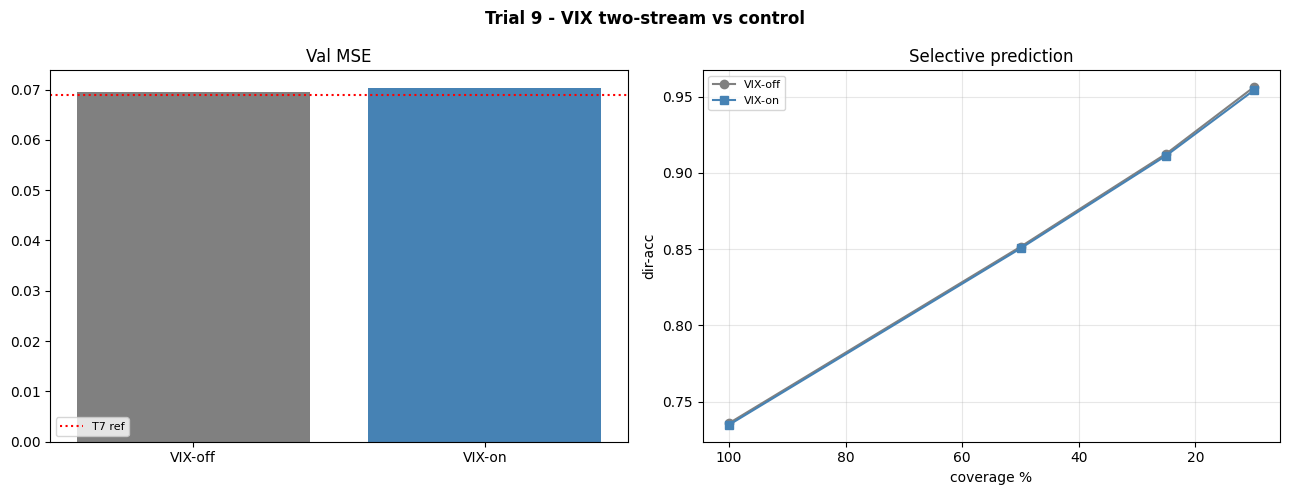


Saved trial9_vix.png


In [8]:
# Cell 8 - Compare: aggregate + selective-prediction coverage curve
def selective_curve(preds):
    iu,ju=np.triu_indices(N_STOCKS,k=1)
    tc=(val_fut-val_cur)[:,iu,ju].reshape(-1); pc=(preds-val_cur)[:,iu,ju].reshape(-1)
    t=np.sign(tc); pm=np.sign(pc); conf=np.abs(pc); nz=t!=0
    order=np.argsort(conf)[::-1]; t_o,pm_o=t[order],pm[order]; nzo=t_o!=0
    covs=np.array([0.10,0.25,0.50,1.00]); acc=[]
    for q in covs:
        k=max(1,int(q*len(order))); sel=nzo[:k]; acc.append(float((pm_o[:k][sel]==t_o[:k][sel]).mean()))
    return covs,acc

m_off=metrics(preds_off,val_fut,val_cur); m_on=metrics(preds_on,val_fut,val_cur)
print(f'{"config":<14}{"MSE":>10}{"Pearson":>9}{"dir":>7}{"vs_mean":>9}')
print('-'*50)
print(f'{"VIX-off":<14}{m_off["mse"]:>10.6f}{m_off["pearson_r"]:>9.4f}{m_off["dir_acc"]:>7.3f}{m_off["vs_mean"]:>+8.1f}%')
print(f'{"VIX-on":<14}{m_on["mse"]:>10.6f}{m_on["pearson_r"]:>9.4f}{m_on["dir_acc"]:>7.3f}{m_on["vs_mean"]:>+8.1f}%')
print(f'{"T7 return ref":<14}{0.068991:>10.6f}{0.3622:>9.4f}{0.729:>7.3f}{3.2:>+8.1f}%')

cov,a_off=selective_curve(preds_off); _,a_on=selective_curve(preds_on)
print(f'\nSelective-prediction dir-acc by coverage:')
print(f'{"coverage":>9}{"VIX-off":>10}{"VIX-on":>10}{"delta":>9}')
for c,ao,an in zip(cov,a_off,a_on):
    print(f'{c*100:>8.0f}%{ao:>10.4f}{an:>10.4f}{(an-ao)*100:>+8.2f}pp')

fig,ax=plt.subplots(1,2,figsize=(13,5)); fig.suptitle('Trial 9 - VIX two-stream vs control',fontweight='bold')
ax[0].bar([0,1],[m_off['mse'],m_on['mse']],color=['gray','steelblue']); ax[0].set_xticks([0,1]); ax[0].set_xticklabels(['VIX-off','VIX-on'])
ax[0].axhline(0.068991,color='red',ls=':',label='T7 ref'); ax[0].set_title('Val MSE'); ax[0].legend(fontsize=8)
ax[1].plot(cov*100,a_off,'o-',color='gray',label='VIX-off'); ax[1].plot(cov*100,a_on,'s-',color='steelblue',label='VIX-on')
ax[1].invert_xaxis(); ax[1].set_xlabel('coverage %'); ax[1].set_ylabel('dir-acc'); ax[1].set_title('Selective prediction'); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS,'trial9_vix.png'),dpi=150,bbox_inches='tight'); plt.show()
print('\nSaved trial9_vix.png')
